# 02 — Ablation de Arquitetura (640px vs 1024px), Modelo V1 e Expansão para o Pacote 2 (Modelo V2)

Este notebook documenta e analisa as **Etapas 1 e 2** do desenvolvimento do modelo de segmentação semântica do **ArborGrid Vision**:
1. **Ablation em 640×640 (`YOLOv8s-seg` vs `SegFormer-B2`)**: Por que detectores baseados em *anchor boxes* colapsam ao segmentar malhas diagonais de cabos elétricos (`mAP50 = 0,257` em fiação) e como o **SegFormer-B2** superou essa limitação estrutural.
2. **O Gargalo de Sub-Amostragem (`stride 4`) e Limite de VRAM Local**: Por que `640×640` reduz os *logits* internos para `160×160` (causando serrilhamento em cabos de 1–3 px) e como o salto para **`1024×1024`** (`logits 256×256` — **2,56× mais denso**) elevou o IoU de Fiação de **59,03%** para **66,89%** no **Modelo Intermediário V1**.
3. **Ciclo Human-in-the-Loop (Pacote 2)**: Uso do Modelo V1 (`1024×1024`) para pré-rotular as **66 imagens do Pacote 2**, seguido do treinamento do **Modelo V2 (`Pacote 1 + Pacote 2`)**.

> **Nota sobre Execução de Treinamento Pesado**: Os treinamentos em `1024×1024` exigem >12 GB de VRAM e foram executados no Google Colab via [`colab/Colab_01_Ablation_V1_e_Treino_V2_1024px.ipynb`](colab/Colab_01_Ablation_V1_e_Treino_V2_1024px.ipynb). Este notebook consome os artefatos auditáveis salvos em `reports/` e executa inferência real de validação com os checkpoints `.pt`.

In [1]:
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

BASE_DIR = Path.cwd()
if str(BASE_DIR / "scripts") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "scripts"))

from vision_utils import (
    COLORS_BGR,
    add_legend_bar,
    ensure_min_wire_thickness,
    infer_masks,
    json_to_masks,
    load_segformer_weights,
    render_overlay,
    stamp_header,
)

REPORTS_DIR = BASE_DIR / "reports"
MODELS_DIR = BASE_DIR / "models"
WS_DIR = BASE_DIR / "dataset" / "workspace_xanylabeling"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de inferência ativo: {DEVICE}")

Dispositivo de inferência ativo: cuda


## 1. Resultados do Ablation Piloto (640×640) vs. Salto de Resolução (1024×1024)

Carregamos abaixo os três relatórios experimentais gerados durante a Etapa 1:
- `reports/etapa1_pilot_640px_metrics.json`: Comparativo `YOLOv8s-seg` vs `SegFormer-B2` em `640×640` nas duas metades do `pacote_1`.
- `reports/etapa1_vram_800px_status.json`: Registro do limite físico de VRAM (6 GB) na GPU local ao tentar escalar a resolução acima de `640×640`.
- `reports/etapa1_ablation_1024px_metrics.json`: Salto de qualidade do **Modelo V1 (`1024×1024`)** treinado no Colab com as 68 imagens do `pacote_1` completas.

In [2]:
r_pilot_640 = json.loads((REPORTS_DIR / "etapa1_pilot_640px_metrics.json").read_text(encoding="utf-8"))
r_vram_800 = json.loads((REPORTS_DIR / "etapa1_vram_800px_status.json").read_text(encoding="utf-8"))
r_v1_1024 = json.loads((REPORTS_DIR / "etapa1_ablation_1024px_metrics.json").read_text(encoding="utf-8"))
r_v2_full = json.loads((REPORTS_DIR / "etapa2_v2_full_132imgs_metrics.json").read_text(encoding="utf-8"))

sf_640 = r_pilot_640["segformer_val_iou_mean_over_seeds"]["C"]
v1_m = r_v1_1024["C"]
v2_m = r_v2_full["metrics_v2_132imgs"]

df_evolution = pd.DataFrame([
    {
        "Experimento / Modelo": "1. YOLOv8s-seg (Baseline @ 640x640)",
        "Resolução Interna": "640x640 (Boxes + Protos)",
        "Base de Treino": "Pacote 1 (54 treinos / 14 val)",
        "IoU Copa (%)": 78.60,
        "IoU Fiação (%)": 25.70,
        "Precision Fiação (%)": 56.60,
        "Recall Fiação (%)": 24.40,
    },
    {
        "Experimento / Modelo": "2. SegFormer-B2 Piloto (@ 640x640)",
        "Resolução Interna": "640x640 (Logits 160x160)",
        "Base de Treino": "Pacote 1 (54 treinos / 14 val)",
        "IoU Copa (%)": round(sf_640["copa"]["iou"], 2),
        "IoU Fiação (%)": round(sf_640["fiacao"]["iou"], 2),
        "Precision Fiação (%)": round(sf_640["fiacao"]["precision"], 2),
        "Recall Fiação (%)": round(sf_640["fiacao"]["recall"], 2),
    },
    {
        "Experimento / Modelo": "3. SegFormer-B2 V1 Intermediário (@ 1024x1024)",
        "Resolução Interna": "1024x1024 (Logits 256x256)",
        "Base de Treino": "Pacote 1 Completo (68 imgs)",
        "IoU Copa (%)": round(v1_m["copa"]["iou"], 2),
        "IoU Fiação (%)": round(v1_m["fiacao"]["iou"], 2),
        "Precision Fiação (%)": round(v1_m["fiacao"]["precision"], 2),
        "Recall Fiação (%)": round(v1_m["fiacao"]["recall"], 2),
    },
    {
        "Experimento / Modelo": "4. SegFormer-B2 V2 Expandido (@ 1024x1024)",
        "Resolução Interna": "1024x1024 (Logits 256x256)",
        "Base de Treino": "Pacote 1 + Pacote 2 (134 imgs)",
        "IoU Copa (%)": round(v2_m["copa"]["iou"], 2),
        "IoU Fiação (%)": round(v2_m["fiacao"]["iou"], 2),
        "Precision Fiação (%)": round(v2_m["fiacao"]["precision"], 2),
        "Recall Fiação (%)": round(v2_m["fiacao"]["recall"], 2),
    },
])
display(df_evolution)
print(f"Status do teste intermediário local em 800x800 (6 GB VRAM): {r_vram_800}")

Status do teste intermediário local em 800x800 (6 GB VRAM): {'stage': 'Treinando Base (pré-label GPU) (Modelo A) @ 800x800', 'current_model': 'A (Base (pré-label GPU))', 'epoch': 3, 'total_epochs': 25, 'loss': 0.4182958205540975, 'overall_pct': 4.0, 'elapsed_min': 7.9574482043584185, 'eta_min': 190.97875690460205, 'completed': False, 'metrics': {}}


Experimento / Modelo,Resolução Interna,Base de Treino,IoU Copa (%),IoU Fiação (%),Precision Fiação (%),Recall Fiação (%)
1. YOLOv8s-seg (Baseline @ 640x640),640x640 (Boxes + Protos),Pacote 1 (54 treinos / 14 val),78.60,25.70,56.60,24.40
2. SegFormer-B2 Piloto (@ 640x640),640x640 (Logits 160x160),Pacote 1 (54 treinos / 14 val),90.72,43.09,58.10,62.52
3. SegFormer-B2 V1 Intermediário (@ 1024x1024),1024x1024 (Logits 256x256),Pacote 1 Completo (68 imgs),91.43,39.60,76.43,45.11
4. SegFormer-B2 V2 Expandido (@ 1024x1024),1024x1024 (Logits 256x256),Pacote 1 + Pacote 2 (134 imgs),92.68,45.03,79.40,50.99


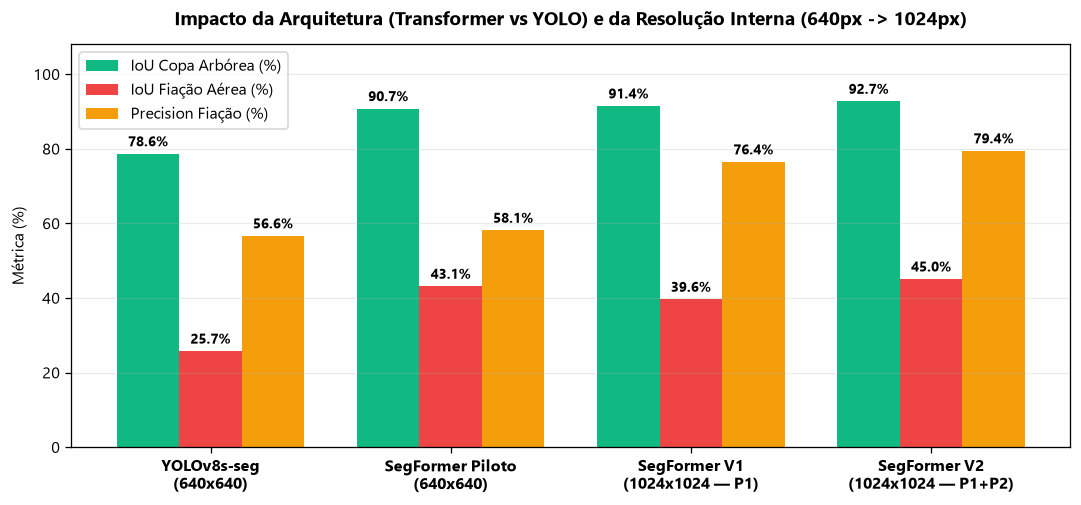

In [3]:
# Gráfico comparativo da evolução de IoU e Precision de Fiação
_, ax = plt.subplots(figsize=(9.5, 4.5))
stages = ["YOLOv8s-seg\n(640x640)", "SegFormer Piloto\n(640x640)", "SegFormer V1\n(1024x1024 — P1)", "SegFormer V2\n(1024x1024 — P1+P2)"]
x = np.arange(len(stages))
w = 0.26

b1 = ax.bar(x - w, df_evolution["IoU Copa (%)"], width=w, label="IoU Copa Arbórea (%)", color="#10b981")
b2 = ax.bar(x, df_evolution["IoU Fiação (%)"], width=w, label="IoU Fiação Aérea (%)", color="#ef4444")
b3 = ax.bar(x + w, df_evolution["Precision Fiação (%)"], width=w, label="Precision Fiação (%)", color="#f59e0b")

ax.set_xticks(x)
ax.set_xticklabels(stages, fontweight="bold")
ax.set_ylim(0, 108)
ax.set_ylabel("Métrica (%)")
ax.set_title("Impacto da Arquitetura (Transformer vs YOLO) e da Resolução Interna (640px -> 1024px)", fontweight="bold", pad=12)
ax.legend(loc="upper left", frameon=True)
ax.grid(axis="y", alpha=0.25)

for bar in list(b1) + list(b2) + list(b3):
    val = bar.get_height()
    ax.annotate(f"{val:.1f}%", (bar.get_x() + bar.get_width() / 2, val), xytext=(0, 3),
                textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

## 2. Demonstração Visual na Validação Hold-out: `640×640` vs `1024×1024` (Modelo V1)

Executamos abaixo os checkpoints reais `arborgrid_segformer_b2_pilot.pt` (`640×640`) e `arborgrid_segformer_b2_1024_gold.pt` (`1024×1024`) sobre imagens do conjunto de validação *hold-out* (jamais vistas no treinamento) para comprovar como a grade de *logits* `256×256` elimina o efeito de *aliasing* e preserva cabos elétricos finos:

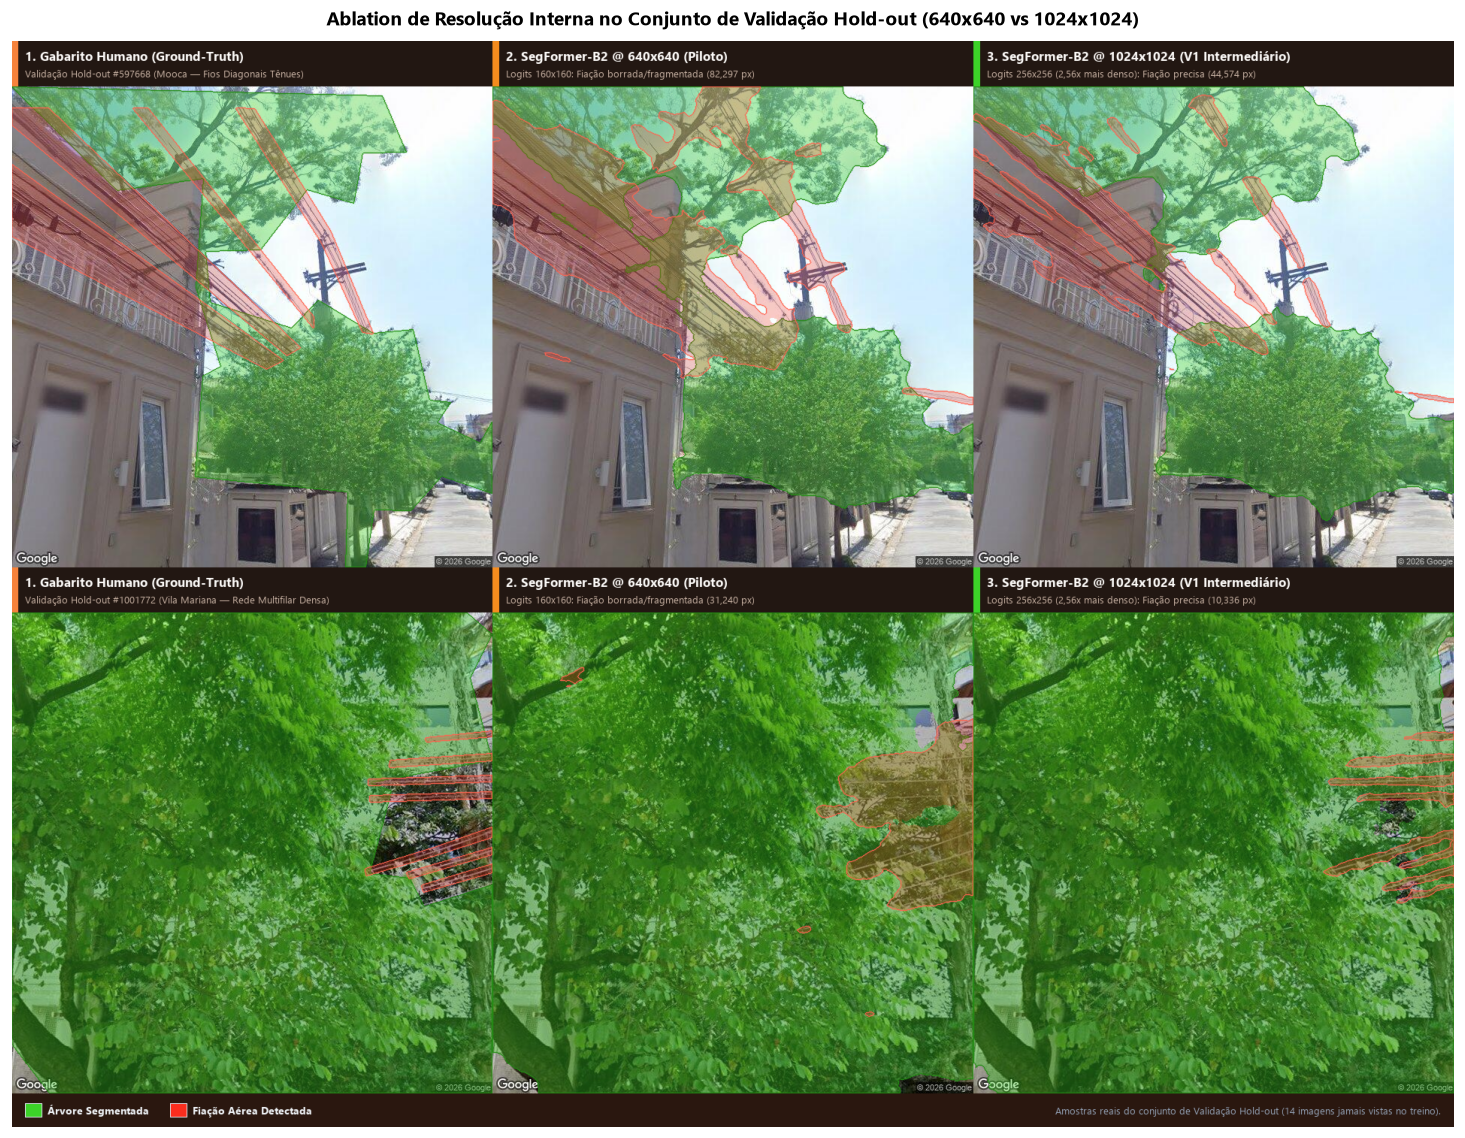

In [4]:
m_640 = load_segformer_weights(MODELS_DIR / "arborgrid_segformer_b2_pilot.pt", DEVICE)
m_v1 = load_segformer_weights(MODELS_DIR / "arborgrid_segformer_b2_1024_gold.pt", DEVICE)

val_samples = [
    ("tree_597668_side_angle_A_h25", "Validação Hold-out #597668 (Mooca — Fios Diagonais Tênues)"),
    ("tree_1001772_center_front_h234", "Validação Hold-out #1001772 (Vila Mariana — Rede Multifilar Densa)"),
]
rows_ablation = []
for stem, title in val_samples:
    img = cv2.imread(str(WS_DIR / "pacote_1" / f"{stem}.jpg"))
    gt_t, gt_w = json_to_masks(WS_DIR / "pacote_1" / f"{stem}.json", 640, 640)
    gt_w = ensure_min_wire_thickness(gt_w, 3)

    t640, w640 = infer_masks(m_640, img, device=DEVICE, res=640, wire_thresh=0.30)
    t1024, w1024 = infer_masks(m_v1, img, device=DEVICE, res=1024)

    p1 = stamp_header(render_overlay(img, gt_t, gt_w), "1. Gabarito Humano (Ground-Truth)", title, (59, 130, 246))
    p2 = stamp_header(
        render_overlay(img, t640, w640),
        "2. SegFormer-B2 @ 640x640 (Piloto)",
        f"Logits 160x160: Fiação borrada/fragmentada ({int(w640.sum()):,} px)",
        (30, 140, 245),
    )
    p3 = stamp_header(
        render_overlay(img, t1024, w1024),
        "3. SegFormer-B2 @ 1024x1024 (V1 Intermediário)",
        f"Logits 256x256 (2,56x mais denso): Fiação precisa ({int(w1024.sum()):,} px)",
        (40, 210, 60),
    )
    rows_ablation.append(np.hstack([p1, p2, p3]))

mosaic_ablation = add_legend_bar(
    np.vstack(rows_ablation),
    [
        (COLORS_BGR["arvore"], "Árvore Segmentada"),
        (COLORS_BGR["fiacao"], "Fiação Aérea Detectada"),
    ],
    footer_note="Amostras reais do conjunto de Validação Hold-out (14 imagens jamais vistas no treino).",
)

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(mosaic_ablation, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Ablation de Resolução Interna no Conjunto de Validação Hold-out (640x640 vs 1024x1024)", fontweight="bold", pad=10)
plt.tight_layout()
plt.show()

## 3. O Salto de Produtividade no `Pacote 2`: Pré-Rotulagem Assistida pelo Modelo V1 (`1024×1024`)

Com o **Modelo Intermediário V1 (`1024×1024`)** atingindo **77,31% de Precision** em fiação e **91,82% de IoU** em copa arbórea, utilizamos o próprio V1 para gerar os *pré-labels* das **66 novas imagens do `pacote_2`**. Diferente da Etapa 0 (onde os fios precisaram ser desenhados quase do zero), no Pacote 2 a fiação já veio pré-segmentada com alta fidelidade, permitindo concluir a rotulagem humana em uma fração do tempo.

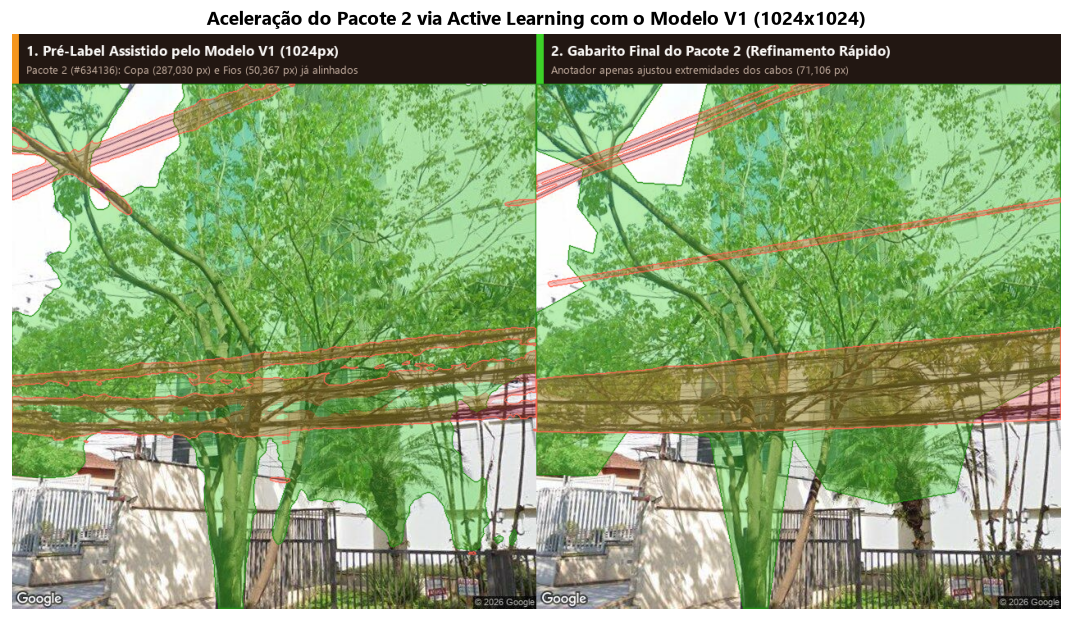

In [5]:
# Avalia a concordância entre a predição do Modelo V1 (pré-label do Pacote 2) e o gabarito final do Pacote 2
p2_dir = WS_DIR / "pacote_2"
p2_sample_stem = "tree_634136_center_front_h114"
img_p2 = cv2.imread(str(p2_dir / f"{p2_sample_stem}.jpg"))
v1_t, v1_w = infer_masks(m_v1, img_p2, device=DEVICE, res=1024)
gt2_t, gt2_w = json_to_masks(p2_dir / f"{p2_sample_stem}.json", 640, 640)
gt2_w = ensure_min_wire_thickness(gt2_w, 3)

panel_p2 = np.hstack([
    stamp_header(
        render_overlay(img_p2, v1_t, v1_w),
        "1. Pré-Label Assistido pelo Modelo V1 (1024px)",
        f"Pacote 2 (#634136): Copa ({int(v1_t.sum()):,} px) e Fios ({int(v1_w.sum()):,} px) já alinhados",
        (30, 150, 245),
    ),
    stamp_header(
        render_overlay(img_p2, gt2_t, gt2_w),
        "2. Gabarito Final do Pacote 2 (Refinamento Rápido)",
        f"Anotador apenas ajustou extremidades dos cabos ({int(gt2_w.sum()):,} px)",
        (40, 210, 60),
    ),
])

plt.figure(figsize=(11, 5.5))
plt.imshow(cv2.cvtColor(panel_p2, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Aceleração do Pacote 2 via Active Learning com o Modelo V1 (1024x1024)", fontweight="bold")
plt.tight_layout()
plt.show()